In [3]:
!pip install shap

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import pickle

In [5]:
# Lets assign categories to probs

# >= 0.70 Critical
# >=0.45 High Risk
# >= 0.20 Medium Risk
# Rest Low Risk

In [6]:
df = pd.read_csv('cleaned_data.csv')

In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,...,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes,Contract One year,Contract Two year,Credit card (automatic),Electronic check,Mailed check,lifetime_value_proxy,spend_consistency
0,7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,...,0,1,0,0,0,0,1,0,29.85,14.925000
1,5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.50,...,0,1,0,1,0,0,0,1,1936.30,53.985714
2,3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,...,0,1,0,0,0,0,0,1,107.70,36.050000
3,7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,...,0,1,0,1,0,0,0,0,1903.50,40.016304
4,9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,...,0,1,0,0,0,0,1,0,141.40,50.550000


In [8]:
X = df.iloc[:, 1:].drop(columns=['Churn'])
y = df['Churn']

In [9]:
ids = df['customerID']

In [10]:
with open('trained_model.pkl', 'rb') as file:
    best_rf = pickle.load(file)

In [11]:
best_rf

,n_estimators,200
,criterion,'gini'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [12]:
df['churn_prob'] = best_rf.predict_proba(X)[:, 1]
df['churn_prob']

0       0.741028
1       0.118941
2       0.597926
3       0.127118
4       0.777242
          ...   
7027    0.212993
7028    0.318382
7029    0.414974
7030    0.783710
7031    0.153351
Name: churn_prob, Length: 7032, dtype: float64

In [13]:
def assign_segment(p):
    if p >= 0.70:   return 'Critical'    # Top priority
    elif p >= 0.45: return 'High Risk'
    elif p >= 0.20: return 'Medium Risk'
    else:           return 'Low Risk'

df['segment'] = df['churn_prob'].apply(assign_segment)
print(df['segment'].value_counts())

segment
Low Risk       2613
Medium Risk    1873
High Risk      1506
Critical       1040
Name: count, dtype: int64


<Axes: xlabel='tenure', ylabel='Count'>

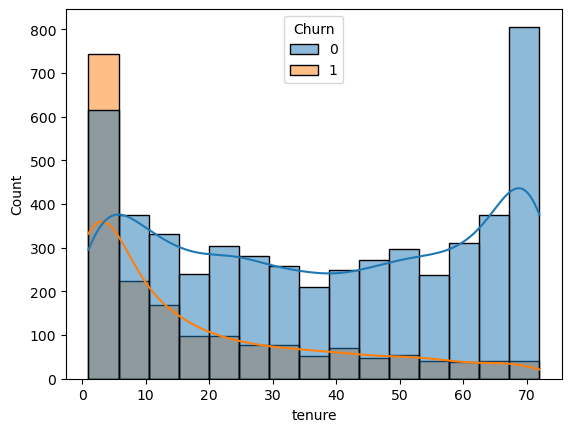

In [14]:
sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    kde=True
)

In [15]:
# SHAP tells us features are pushing this specific customer toward churning.
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X)

# Handle binary classifier output
if isinstance(shap_values, list):
    sv = shap_values[1]   # older SHAP versions
else:
    # newer SHAP versions -> (samples, features, classes)
    if len(shap_values.shape) == 3:
        sv = shap_values[:, :, 1]
    else:
        sv = shap_values

feature_names = X.columns.tolist()

def top_drivers(shap_row, n=3):
    idx = np.argsort(shap_row)[::-1][:n]
    return [(feature_names[int(i)], round(float(shap_row[i]), 3)) for i in idx]

df['top_drivers'] = [top_drivers(sv[i]) for i in range(len(df))]

In [16]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,...,Contract One year,Contract Two year,Credit card (automatic),Electronic check,Mailed check,lifetime_value_proxy,spend_consistency,churn_prob,segment,top_drivers
0,7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,...,0,0,0,1,0,29.85,14.925000,0.741028,Critical,"[(tenure, 0.097), (TotalCharges, 0.072), (life..."
1,5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.50,...,1,0,0,0,1,1936.30,53.985714,0.118941,Low Risk,"[(TechSupport_No, 0.023), (Contract Two year, ..."
2,3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,...,0,0,0,0,1,107.70,36.050000,0.597926,High Risk,"[(tenure, 0.092), (lifetime_value_proxy, 0.067..."
3,7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,...,1,0,0,0,0,1903.50,40.016304,0.127118,Low Risk,"[(Contract Two year, 0.022), (OnlineBackup_No,..."
4,9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,...,0,0,0,1,0,141.40,50.550000,0.777242,Critical,"[(tenure, 0.077), (lifetime_value_proxy, 0.046..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,6840-RESVB,1,0,1,1,24,1,1,84.80,1990.50,...,1,0,0,0,1,2035.20,79.620000,0.212993,Medium Risk,"[(Contract Two year, 0.03), (OnlineBackup_No, ..."
7028,2234-XADUH,0,0,1,1,72,1,1,103.20,7362.90,...,1,0,1,0,0,7430.40,100.861644,0.318382,Medium Risk,"[(OnlineSecurity_No, 0.039), (Fiber optic, 0.0..."
7029,4801-JZAZL,0,0,1,1,11,0,1,29.60,346.45,...,0,0,0,1,0,325.60,28.870833,0.414974,Medium Risk,"[(Electronic check, 0.048), (TechSupport_No, 0..."
7030,8361-LTMKD,1,1,1,0,4,1,1,74.40,306.60,...,0,0,0,0,1,297.60,61.320000,0.783710,Critical,"[(tenure, 0.08), (OnlineSecurity_No, 0.047), (..."


In [17]:
df[df['segment'] == 'High Risk'][['top_drivers', 'tenure']]

,top_drivers,tenure
2,"[(tenure, 0.092), (lifetime_value_proxy, 0.067...",2
6,"[(Fiber optic, 0.05), (TechSupport_No, 0.039),...",22
8,"[(Fiber optic, 0.056), (Electronic check, 0.04...",28
13,"[(Fiber optic, 0.051), (OnlineSecurity_No, 0.0...",49
14,"[(Fiber optic, 0.056), (MonthlyCharges, 0.04),...",25
...,...,...
7005,"[(tenure, 0.098), (TotalCharges, 0.067), (life...",1
7012,"[(Fiber optic, 0.046), (TechSupport_No, 0.041)...",63
7014,"[(Fiber optic, 0.054), (OnlineSecurity_No, 0.0...",18
7018,"[(OnlineSecurity_No, 0.046), (TechSupport_No, ...",6


In [18]:
# Based on top drivers we can create personalized offers


df.to_csv('segmented_users_drivers.csv')


In [19]:
INTERVENTION_RULES = {
 
    # ── CRITICAL SEGMENT ──────────────────────────────────────────────
    # Avg tenure: 4.9 months | 83% have tenure as #1 driver
    # 98% have no OnlineSecurity, 95% no TechSupport, 73% on Electronic check
    # Strategy: STOP the bleed — act within 48 hours, human touch required
 
    ("Critical", "tenure"): {
        "offer":     "New customer survival bundle: Free OnlineSecurity + TechSupport for 3 months",
        "rationale": "83% of Critical customers list tenure as top driver. At avg 4.9 months, "
                     "they haven't formed habits yet. A free bundle boosts stickiness before "
                     "they decide to leave.",
        "channel":   "Direct call within 48 hours",
        "discount":  0,
        "cost_type": "Free add-on (no revenue loss)",
        "urgency":   "HIGH — act within 48 hours",
    },
 
    ("Critical", "Fiber optic"): {
        "offer":     "Fibre VIP retention: Free router upgrade + 15% loyalty discount for 6 months",
        "rationale": "Fibre customers pay ₹75.99/mo avg but churn fast when value isn't felt. "
                     "Hardware gift is tangible; the discount locks them in for a re-evaluation period.",
        "channel":   "Direct call + follow-up SMS",
        "discount":  15,
        "cost_type": "Discount + hardware cost",
        "urgency":   "HIGH — act within 48 hours",
    },
 
    ("Critical", "Electronic check"): {
        "offer":     "Auto-pay switch incentive: 1 month free bill credit upon switching to auto-pay",
        "rationale": "73% of Critical customers use Electronic check — a payment method strongly "
                     "correlated with churn. Removing payment friction and rewarding the switch "
                     "reduces both churn risk and late payment risk.",
        "channel":   "Direct call + in-app prompt",
        "discount":  0,
        "cost_type": "1-month bill credit (~₹76)",
        "urgency":   "HIGH",
    },
 
    ("Critical", "OnlineSecurity_No"): {
        "offer":     "Free OnlineSecurity activation + guided setup call",
        "rationale": "98% of Critical customers lack OnlineSecurity. Adding a meaningful "
                     "service at zero cost increases perceived value and product depth.",
        "channel":   "Direct call",
        "discount":  0,
        "cost_type": "Free add-on",
        "urgency":   "HIGH",
    },
 
    ("Critical", "lifetime_value_proxy"): {
        "offer":     "Early-tenure loyalty recognition: Personalised call + tailored plan review",
        "rationale": "Avg LTV of only ₹414 means these customers haven't yet invested enough "
                     "to feel switching costs. A plan review may find a better-fit package "
                     "before they explore competitors.",
        "channel":   "Direct call — senior retention agent",
        "discount":  10,
        "cost_type": "Discount on reviewed plan",
        "urgency":   "HIGH",
    },
 
    # ── HIGH RISK SEGMENT ─────────────────────────────────────────────
    # Avg tenure: 20.8 months | 62% have Fiber optic as #1 driver
    # 53% on Electronic check, 76% no OnlineSecurity, 76% no TechSupport
    # Strategy: ADDRESS the pain point — targeted email/SMS, no cold calls needed
 
    ("High Risk", "Fiber optic"): {
        "offer":     "Fibre loyalty speed boost: Free speed tier upgrade for 3 months",
        "rationale": "62% of High Risk customers are Fibre users. At 20.8 months avg tenure "
                     "they've been loyal enough to merit a reward. A speed upgrade is high "
                     "perceived value at low cost.",
        "channel":   "Email + SMS",
        "discount":  0,
        "cost_type": "Speed tier upgrade (low marginal cost)",
        "urgency":   "MEDIUM — act within 7 days",
    },
 
    ("High Risk", "tenure"): {
        "offer":     "Milestone reward: ₹200 bill credit at 24-month anniversary",
        "rationale": "31% of High Risk customers cite tenure. At ~20 months they're approaching "
                     "the 2-year mark — a milestone reward creates a near-term reason to stay.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "₹200 bill credit",
        "urgency":   "MEDIUM",
    },
 
    ("High Risk", "Electronic check"): {
        "offer":     "Auto-pay switch: ₹100 bill credit upon switching to auto-pay",
        "rationale": "53% of High Risk customers use Electronic check. Incentivising a switch "
                     "to auto-pay reduces churn risk and improves payment reliability.",
        "channel":   "SMS + Email",
        "discount":  0,
        "cost_type": "₹100 bill credit",
        "urgency":   "MEDIUM",
    },
 
    ("High Risk", "OnlineSecurity_No"): {
        "offer":     "Free 3-month OnlineSecurity trial — activate in one click",
        "rationale": "76% lack OnlineSecurity. A free trial with a dead-simple activation CTA "
                     "adds a sticky service at zero acquisition cost.",
        "channel":   "Email with in-app deep link",
        "discount":  0,
        "cost_type": "Free trial (service cost only)",
        "urgency":   "MEDIUM",
    },
 
    ("High Risk", "TechSupport_No"): {
        "offer":     "Priority TechSupport: 1 month free upgrade + dedicated support line",
        "rationale": "76% have no TechSupport. Frustration with service issues is a top "
                     "silent churn driver. Proactively resolving this before they complain works.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "Free add-on (1 month)",
        "urgency":   "MEDIUM",
    },
 
    # ── MEDIUM RISK SEGMENT ───────────────────────────────────────────
    # Avg tenure: 34.6 months | Mixed drivers — Fiber(39%), Security(18%), tenure(18%)
    # 30% Electronic check, 52% no OnlineSecurity, 52% no TechSupport
    # Strategy: BUILD VALUE — education-first, discount-last
 
    ("Medium Risk", "Fiber optic"): {
        "offer":     "Fibre customer value report: Personalised usage summary + tips to get more from the plan",
        "rationale": "39% of Medium Risk are Fibre users. At 34.6 months they know the product "
                     "but may feel it's commodity. A usage report reframes value without discounting.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "Zero cost (content only)",
        "urgency":   "LOW — act within 14 days",
    },
 
    ("Medium Risk", "OnlineSecurity_No"): {
        "offer":     "Security feature education email + 50% off OnlineSecurity for 6 months",
        "rationale": "53% lack OnlineSecurity. At medium risk, a half-price offer is enough "
                     "to convert without the full cost of a free trial.",
        "channel":   "Email",
        "discount":  50,
        "cost_type": "50% discount on add-on",
        "urgency":   "LOW",
    },
 
    ("Medium Risk", "TechSupport_No"): {
        "offer":     "TechSupport feature highlight: '3 problems we solved for customers like you'",
        "rationale": "52% lack TechSupport. Education-first content (real use cases) converts "
                     "better than a generic discount for medium-risk customers.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "Zero cost (content only)",
        "urgency":   "LOW",
    },
 
    ("Medium Risk", "Electronic check"): {
        "offer":     "Auto-pay education + ₹50 credit on switch",
        "rationale": "30% on Electronic check. Smaller incentive than higher segments — "
                     "medium risk doesn't justify full bill credit.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "₹50 credit",
        "urgency":   "LOW",
    },
 
    ("Medium Risk", "tenure"): {
        "offer":     "Annual plan upgrade: 2 months free on annual commitment",
        "rationale": "At 34 months avg tenure, these customers have proven loyalty. "
                     "An annual plan offer locks in revenue while rewarding that loyalty.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "2 months free (~16.7% effective discount)",
        "urgency":   "LOW",
    },
 
    ("Medium Risk", "Contract Two year"): {
        "offer":     "Early renewal bonus: Lock in current rate before next price review",
        "rationale": "Contract Two year as a driver signals they're tracking contract end. "
                     "An early renewal offer with rate-lock creates urgency to stay.",
        "channel":   "Email",
        "discount":  5,
        "cost_type": "5% rate lock discount",
        "urgency":   "LOW",
    },
 
    # ── LOW RISK SEGMENT ──────────────────────────────────────────────
    # Avg tenure: 48.5 months | Top drivers are contract types (41%) — not churn signals
    # Strategy: GROW — upsell, cross-sell, referral, loyalty rewards
 
    ("Low Risk", "Contract Two year"): {
        "offer":     "Loyalty VIP: Early renewal at locked rate + free add-on of choice",
        "rationale": "Contract type as top driver for Low Risk means the model sees contract "
                     "end as the only real risk. An early renewal with a perk pre-empts that window.",
        "channel":   "Email + in-app",
        "discount":  0,
        "cost_type": "Free add-on (customer's choice)",
        "urgency":   "LOW — contact 60 days before contract end",
    },
 
    ("Low Risk", "Contract One year"): {
        "offer":     "Upgrade to 2-year plan: Save 10% vs monthly equivalent",
        "rationale": "One-year customers are prime candidates for two-year upsell. "
                     "They've proven loyalty; a longer commitment benefits both sides.",
        "channel":   "Email",
        "discount":  10,
        "cost_type": "10% discount vs monthly rate",
        "urgency":   "LOW",
    },
 
    ("Low Risk", "OnlineSecurity_No"): {
        "offer":     "Upsell: Add OnlineSecurity + OnlineBackup bundle at ₹X/mo",
        "rationale": "Low risk + no security = clean upsell opportunity. "
                     "No retention discount needed — this is expansion revenue.",
        "channel":   "In-app + email",
        "discount":  0,
        "cost_type": "Paid upsell — no discount",
        "urgency":   "LOW",
    },
 
    ("Low Risk", "TechSupport_No"): {
        "offer":     "Referral programme invitation: Refer a friend, get 1 month free",
        "rationale": "Low risk, long-tenure customers are your best brand advocates. "
                     "Channel their loyalty into acquisition.",
        "channel":   "Email + in-app",
        "discount":  0,
        "cost_type": "1 month credit per referral",
        "urgency":   "LOW",
    },
 
    ("Low Risk", "Fiber optic"): {
        "offer":     "Premium tier upsell: Upgrade to Business Fibre at introductory rate",
        "rationale": "Long-tenure Fibre users are your highest-value segment. "
                     "Offer a premium tier to grow ARPU before a competitor does.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "Introductory pricing on higher tier",
        "urgency":   "LOW",
    },
 
    ("Low Risk", "Electronic check"): {
        "offer":     "Auto-pay switch: ₹50 credit — simple account hygiene improvement",
        "rationale": "Even low-risk Electronic check users benefit from auto-pay. "
                     "Small incentive, reduces payment failure risk.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "₹50 credit",
        "urgency":   "LOW",
    },
 
    ("Low Risk", "PaperlessBilling"): {
        "offer":     "Loyalty recognition email: 'Thank you for being with us X years'",
        "rationale": "PaperlessBilling as driver means these customers are digitally engaged. "
                     "A genuine appreciation message strengthens the relationship at zero cost.",
        "channel":   "Email",
        "discount":  0,
        "cost_type": "Zero cost",
        "urgency":   "LOW",
    },
}
 
# Fallback rules when driver doesn't match any specific rule
SEGMENT_FALLBACKS = {
    "Critical":    ("Personalised retention call — understand the customer's concerns", "Direct call", 10),
    "High Risk":   ("Feature value email + 5% loyalty discount", "Email", 5),
    "Medium Risk": ("Annual plan offer — 2 months free", "Email", 0),
    "Low Risk":    ("Upsell: Add streaming bundle", "In-app", 0),
}

In [24]:
def get_top_driver(top_drivers_str):
    """
    Robustly parse the top_drivers string and return the #1 driver name.
 
    Handles all known CSV serialisation variants:
      - "[('tenure', 0.097), ...]"          standard
      - "\"[('tenure', 0.097), ...]\""      extra outer quotes (Excel / some CSV writers)
      - "[(tenure, 0.097), ...]"            unquoted feature names (repr without quotes)
    """
    import re
    s = str(top_drivers_str).strip().strip('"').strip("'")
 
    # ① Try ast.literal_eval first (handles properly-quoted strings)
    try:
        result = ast.literal_eval(s)
        if result and isinstance(result[0], (list, tuple)):
            return result[0][0]
    except Exception:
        pass
 
    # ② Regex fallback — works even when feature names have no quotes
    #    Matches the first token inside the first tuple: [( <name> , <value>
    match = re.search(r'[\(\[]\s*["\']?([A-Za-z_][A-Za-z0-9_ ]*)["\']?\s*,', s)
    if match:
        return match.group(1).strip()
 
    return None
 
 
def recommend_intervention(row):
    seg = row["segment"]
    driver = row["top_driver"]
 
    # Exact match
    key = (seg, driver)
    if key in INTERVENTION_RULES:
        rule = INTERVENTION_RULES[key]
        return pd.Series({
            "offer":     rule["offer"],
            "channel":   rule["channel"],
            "discount":  rule["discount"],
            "cost_type": rule["cost_type"],
            "urgency":   rule["urgency"],
            "rationale": rule["rationale"],
        })
 
    # Fallback to segment default
    offer, channel, discount = SEGMENT_FALLBACKS.get(
        seg, ("Standard retention email", "Email", 5)
    )
    return pd.Series({
        "offer":     offer,
        "channel":   channel,
        "discount":  discount,
        "cost_type": "Varies",
        "urgency":   "MEDIUM" if seg in ("Critical", "High Risk") else "LOW",
        "rationale": f"No specific rule matched for ({seg}, {driver}) — using segment default.",
    })
 

In [25]:

 
df["top_driver"] = df["top_drivers"].apply(get_top_driver)
 
intervention_cols = df.apply(recommend_intervention, axis=1)
# Drop any pre-existing columns that would clash before joining
df = df.drop(columns=[c for c in intervention_cols.columns if c in df.columns], errors="ignore")
df = pd.concat([df, intervention_cols], axis=1)
 

In [26]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,...,churn_prob,segment,top_drivers,top_driver,offer,channel,discount,cost_type,urgency,rationale
0,7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,...,0.741028,Critical,"[(tenure, 0.097), (TotalCharges, 0.072), (life...",tenure,New customer survival bundle: Free OnlineSecur...,Direct call within 48 hours,0,Free add-on (no revenue loss),HIGH — act within 48 hours,83% of Critical customers list tenure as top d...
1,5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.50,...,0.118941,Low Risk,"[(TechSupport_No, 0.023), (Contract Two year, ...",TechSupport_No,"Referral programme invitation: Refer a friend,...",Email + in-app,0,1 month credit per referral,LOW,"Low risk, long-tenure customers are your best ..."
2,3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,...,0.597926,High Risk,"[(tenure, 0.092), (lifetime_value_proxy, 0.067...",tenure,Milestone reward: ₹200 bill credit at 24-month...,Email,0,₹200 bill credit,MEDIUM,31% of High Risk customers cite tenure. At ~20...
3,7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,...,0.127118,Low Risk,"[(Contract Two year, 0.022), (OnlineBackup_No,...",Contract Two year,Loyalty VIP: Early renewal at locked rate + fr...,Email + in-app,0,Free add-on (customer's choice),LOW — contact 60 days before contract end,Contract type as top driver for Low Risk means...
4,9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,...,0.777242,Critical,"[(tenure, 0.077), (lifetime_value_proxy, 0.046...",tenure,New customer survival bundle: Free OnlineSecur...,Direct call within 48 hours,0,Free add-on (no revenue loss),HIGH — act within 48 hours,83% of Critical customers list tenure as top d...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,6840-RESVB,1,0,1,1,24,1,1,84.80,1990.50,...,0.212993,Medium Risk,"[(Contract Two year, 0.03), (OnlineBackup_No, ...",Contract Two year,Early renewal bonus: Lock in current rate befo...,Email,5,5% rate lock discount,LOW,Contract Two year as a driver signals they're ...
7028,2234-XADUH,0,0,1,1,72,1,1,103.20,7362.90,...,0.318382,Medium Risk,"[(OnlineSecurity_No, 0.039), (Fiber optic, 0.0...",OnlineSecurity_No,Security feature education email + 50% off Onl...,Email,50,50% discount on add-on,LOW,"53% lack OnlineSecurity. At medium risk, a hal..."
7029,4801-JZAZL,0,0,1,1,11,0,1,29.60,346.45,...,0.414974,Medium Risk,"[(Electronic check, 0.048), (TechSupport_No, 0...",Electronic check,Auto-pay education + ₹50 credit on switch,Email,0,₹50 credit,LOW,30% on Electronic check. Smaller incentive tha...
7030,8361-LTMKD,1,1,1,0,4,1,1,74.40,306.60,...,0.783710,Critical,"[(tenure, 0.08), (OnlineSecurity_No, 0.047), (...",tenure,New customer survival bundle: Free OnlineSecur...,Direct call within 48 hours,0,Free add-on (no revenue loss),HIGH — act within 48 hours,83% of Critical customers list tenure as top d...


In [27]:
print("=" * 65)
print("INTERVENTION ASSIGNMENT SUMMARY")
print("=" * 65)
 
summary = (
    df.groupby(["segment", "offer"])
    .agg(
        customers=("customerID", "count"),
        avg_churn_prob=("churn_prob", "mean"),
        avg_ltv=("lifetime_value_proxy", "mean"),
        avg_monthly_charge=("MonthlyCharges", "mean"),
        avg_discount=("discount", "mean"),
    )
    .round(2)
    .sort_values(["segment", "customers"], ascending=[True, False])
)
print(summary.to_string())
 
print("\n\nCUSTOMERS PER SEGMENT")
print(df["segment"].value_counts().to_string())
 
print("\n\nOFFER COVERAGE CHECK (unmapped customers)")
unmatched = df[df["rationale"].str.startswith("No specific rule")]
print(f"Unmatched: {len(unmatched)} / {len(df)} ({100*len(unmatched)/len(df):.1f}%)")
if len(unmatched) > 0:
    print("Unmatched drivers:", unmatched["top_driver"].value_counts().to_dict())

INTERVENTION ASSIGNMENT SUMMARY
                                                                                                      customers  avg_churn_prob  avg_ltv  avg_monthly_charge  avg_discount
segment     offer                                                                                                                                                         
Critical    New customer survival bundle: Free OnlineSecurity + TechSupport for 3 months                    866            0.80   249.06               73.18           0.0
            Fibre VIP retention: Free router upgrade + 15% loyalty discount for 6 months                    174            0.75  1236.59               90.02          15.0
High Risk   Fibre loyalty speed boost: Free speed tier upgrade for 3 months                                 940            0.57  2775.27               90.18           0.0
            Milestone reward: ₹200 bill credit at 24-month anniversary                                      472  

In [28]:
output_cols = [
    "customerID", "segment", "churn_prob", "top_driver",
    "MonthlyCharges", "tenure", "lifetime_value_proxy",
    "offer", "channel", "discount", "cost_type", "urgency", "rationale",
]
df[output_cols].to_csv("intervention_recommendations.csv", index=False)
print("\nSaved: intervention_recommendations.csv")


Saved: intervention_recommendations.csv
